In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [78]:
from pathlib import Path

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent 

df = pd.read_csv(project_dir/"data"/ "hour.csv")

df.head(1)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16


In [11]:
df.shape
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

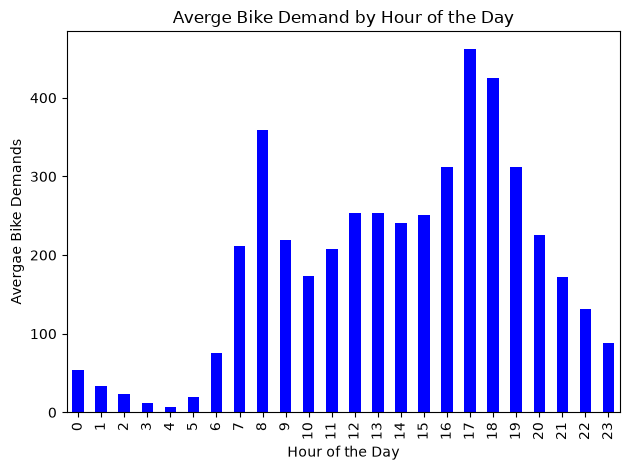

In [74]:
df.groupby("hr")["cnt"].mean().plot(kind = "bar", color = "blue")

plt.title("Averge Bike Demand by Hour of the Day")

plt.xlabel("Hour of the Day")

plt.ylabel("Avergae Bike Demands")
plt.tight_layout()
plt.savefig(
    project_dir / "figures" / "hourly_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Research Question 1 - How does bicycle rental demand vary throughout the day?

### Findings
Looking at the bar chart, average hourly bicycle indicate two peaks, occuring at 8 and 5-6pm, with demand remaining low early in the moring and increasing during peak periods.


### Possible Explanation
One possible explanation for the morning and evening peaks is commuter behaviour. The peaks coincidie with typical working hours 

### Limitations
The patterns is consistent with commuting behaviour, but isnt sufficient to suggest it is the only reason; other factors such as temperature, city, season can explain the pattern as well. 
Therefore, we cannot conclude that only commuting causes these peaks without ruling out alternative explanations or controlling for them. 

/Users/ramanprasad/Documents/bike_sharing_demand_analysis


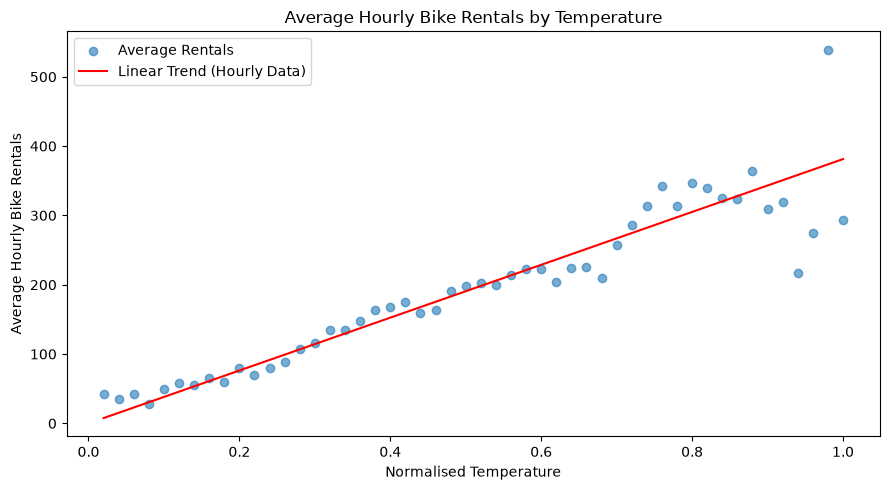

In [80]:
from pathlib import Path

project_dr = Path.cwd()

if project_dr.name == "notebooks":
    project_dr = project_dr.parent

print(project_dr)

z = np.polyfit(df["temp"], df["cnt"], 1)
p = np.poly1d(z)

plt.figure(figsize=(9, 5))

plt.scatter(
    temp_avg["temp"],
    temp_avg["cnt"],
    alpha=0.6,
    label="Average Rentals"
)

plt.plot(
    np.sort(df["temp"].unique()),
    p(np.sort(df["temp"].unique())),
    color="red",
    label="Linear Trend (Hourly Data)"
)

plt.title("Average Hourly Bike Rentals by Temperature")
plt.xlabel("Normalised Temperature")
plt.ylabel("Average Hourly Bike Rentals")
plt.legend()
plt.tight_layout()

plt.savefig(
    project_dr / "figures" / "temperature_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Research Question 2: How is temperature associated with hourly bicycle rental demand?

**Findings**

The exploratory analysis suggests a moderate positive linear relationship between temperature and hourly bicycle rental demand (Pearson's r = 0.40). This indicates that higher temperatures tend to be associated with higher rental counts, although considerable variability remains.

**Possible Explanation**

Warmer weather may encourage cycling by making outdoor travel more comfortable. However, other factors such as time of day, season, and weather conditions may also influence rental demand.

**Limitations**

The observed correlation does not establish a causal relationship between temperature and bicycle rentals. Additionally, the correlation describes the overall linear association and may not capture nonlinear relationships or differences across seasons.



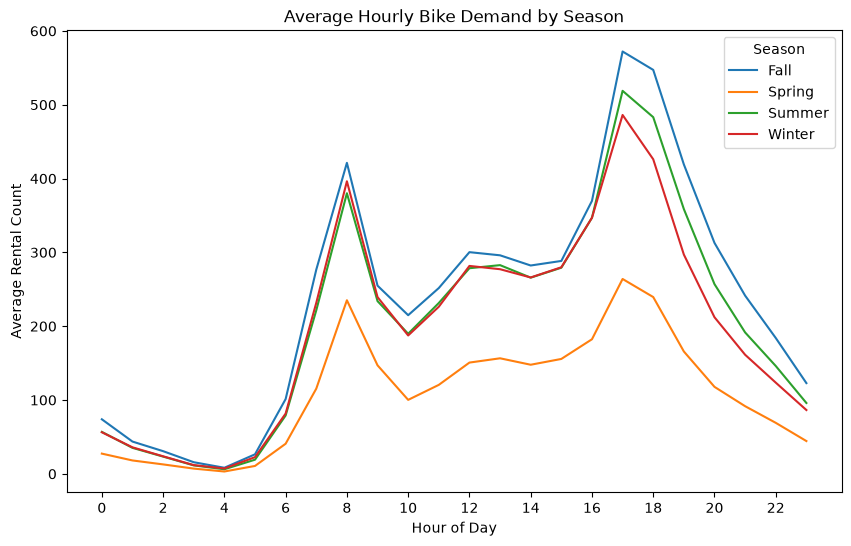

In [73]:
df["season_name"] = df["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

season_hour_avg = (
    df.groupby(["season_name", "hr"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

for season in season_hour_avg["season_name"].unique():

    subset = season_hour_avg[
        season_hour_avg["season_name"] == season
    ]

    plt.plot(
        subset["hr"],
        subset["cnt"],
        label=season
    )

plt.title("Average Hourly Bike Demand by Season")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rental Count")
plt.xticks(range(0, 24, 2))
plt.legend(title="Season")
plt.show()

### RQ2: How is season associated with bicycle rental demand?

**Findings**

Average hourly bicycle rental demand follows a similar pattern across all four seasons, with noticeable peaks around 8 AM and 5–6 PM.

However, the magnitude of demand differs considerably between seasons. Autumn generally exhibits the highest average hourly rental counts, while spring exhibits the lowest. These differences are particularly noticeable during peak hours.

**Possible Explanation**

The consistency of morning and evening peaks across seasons may reflect regular commuting behaviour.

Seasonal differences in rental demand could be associated with changes in temperature, weather conditions, and cycling preferences. However, the higher demand observed during autumn compared with summer suggests that temperature alone may not fully explain seasonal differences.

**Limitations**

The analysis is descriptive and does not establish that season directly causes changes in rental demand. Other factors, including weather conditions, holidays, and changes in bicycle usage over time, could contribute to the observed differences.